# Week 6: age-wise temporal Grad-CAM on validation ECGs

Run `Week6_Age_Behaviour.ipynb` first. This notebook uses its reproduced validation predictions and examines **twelve-lead records only**, with the fixed disease-labelled Week 5 unweighted ResNet and multi-scale ResNet in **separate** analyses. The target remains the 19 selected exact ICD-10 code strings, not ECG diagnostic statements. No training, threshold tuning, or test-set access occurs.

**Selection rule (before viewing maps):** within each model × age group × TP/TN/FP/FN outcome at threshold 0.5, retain one record per patient closest to that pool's median positive score; sort those patient representatives by score and choose up to seven evenly spaced score ranks. The figure uses the selected case closest to the pool median. Every selected record is recorded in `gradcam_cases.csv`. Outcomes and scores determine sampling; heatmap appearance never does. This score-stratified subset is descriptive, not a random or representative sample of all cases.

**Attribution:** hook the output of the final residual block's second convolution, backpropagate the **positive-class logit** for every outcome, average gradients over time to weight channels, sum, apply ReLU, and interpolate to 5,000 input samples. Each temporal map is shared across displayed leads because the layer has already mixed channels. Maps from the two architectures are not pooled or compared by raw magnitude. A bright interval does not establish a cardiac feature or disease mechanism. We summarize the fraction of positive Grad-CAM mass in its highest one-second window as a descriptive concentration measure; all-zero maps are counted separately.

In [1]:
from pathlib import Path
import sys, os, importlib.util
import numpy as np, pandas as pd, torch, torch.nn.functional as F, wfdb
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from IPython.display import display
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'Data/AttributesDictionary.csv').is_file())
OUT=ROOT/'new work/Week6/experimental/age_analysis';RECORDS=ROOT/'Child_ECG/Child_ecg'
FS=500; N_SAMPLES=5000; THRESHOLD=.5; K_PER_CELL=7
assert Path(sys.executable).resolve()==(ROOT/'venv/bin/python').resolve()
assert torch.cuda.is_available(), 'CUDA unavailable in this notebook kernel.'
DEVICE=torch.device('cuda');torch.set_num_threads(min(4,os.cpu_count() or 1))
print('Python',sys.executable,'Torch',torch.__version__,'GPU',torch.cuda.get_device_name(0))
predictions=pd.read_csv(OUT/'validation_predictions.csv')
assert len(predictions)==2169 and predictions.target.sum()==583
frame=predictions[predictions.lead_count==12].copy()
assert len(frame)==1888 and frame.target.sum()==426 and frame.patient_id.nunique()==1555
AGE_GROUPS=['<2','2–<6','6–<12','>=12'];OUTCOMES=['TP','TN','FP','FN']
LEADS=['I','II','III','AVR','AVL','AVF','V1','V2','V3','V4','V5','V6'];lead_index={v:i for i,v in enumerate(LEADS)}
def import_class(name,path,class_name):
    spec=importlib.util.spec_from_file_location(name,path);module=importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module);return getattr(module,class_name)
ResNet1D=import_class('week5_models',ROOT/'NoteBooks/Week5/models.py','ResNet1D')
MultiScaleResNet1D=import_class('week8_models',ROOT/'NoteBooks/Week8/ExperimentB/models.py','MultiScaleResNet1D')
paths={'week5_resnet_unweighted':(ResNet1D,ROOT/'new work/Week5/disease_labelled/resnet_unweighted_best.pth'),
       'multiscale_resnet':(MultiScaleResNet1D,ROOT/'new work/Week5/experimental/multiscale_resnet_best.pth')}
models={}
for name,(cls,path) in paths.items():
    ck=torch.load(path,map_location=DEVICE,weights_only=False)
    assert ck['lead_order']==LEADS and ck['input_samples']==N_SAMPLES
    model=cls(2).to(DEVICE);model.load_state_dict(ck['model_state_dict']);model.eval()
    models[name]=model
print('Frozen models loaded',list(models))

Python /home/souhit/Documents/Research/Pediatric_ECG/venv/bin/python Torch 2.6.0+cu124 GPU NVIDIA GeForce RTX 3060 Laptop GPU
Frozen models loaded ['week5_resnet_unweighted', 'multiscale_resnet']


In [2]:
def outcome(y,p):
    pred=int(p>=THRESHOLD)
    return 'TP' if y==1 and pred==1 else 'FN' if y==1 else 'FP' if pred==1 else 'TN'
selections=[];pools=[]
for name in models:
    tmp=frame.copy();tmp['score']=tmp[name+'_probability']
    tmp['outcome']=[outcome(y,p) for y,p in zip(tmp.target,tmp.score)]
    for age in AGE_GROUPS:
        for cat in OUTCOMES:
            pool=tmp[(tmp.age_group==age)&(tmp.outcome==cat)].copy()
            pools.append({'model':name,'age_group':age,'outcome':cat,'pool_records':len(pool),
                          'pool_patients':pool.patient_id.nunique()})
            if pool.empty:continue
            median=pool.score.median()
            representatives=(pool.assign(distance=(pool.score-median).abs())
                              .sort_values(['distance','validation_index'])
                              .drop_duplicates('patient_id')
                              .sort_values(['score','validation_index']).reset_index(drop=True))
            k=min(K_PER_CELL,len(representatives))
            positions=np.unique(np.rint(np.linspace(0,len(representatives)-1,k)).astype(int))
            selected=representatives.iloc[positions].copy()
            figure_index=int(selected.iloc[(selected.score-median).abs().argmin()].validation_index)
            for rank,(_,r) in enumerate(selected.iterrows()):
                selections.append({'model':name,'age_group':age,'outcome':cat,
                                   'validation_index':int(r.validation_index),'patient_id':r.patient_id,
                                   'filename':r.filename,'target':int(r.target),'positive_score':float(r.score),
                                   'pool_records':len(pool),'pool_patients':pool.patient_id.nunique(),
                                   'selected_rank':rank,'figure_case':int(r.validation_index)==figure_index})
selection=pd.DataFrame(selections);pool_summary=pd.DataFrame(pools)
assert not selection.duplicated(['model','age_group','outcome','patient_id']).any()
selection.to_csv(OUT/'gradcam_selection.csv',index=False)
pool_summary.to_csv(OUT/'gradcam_pool_counts.csv',index=False)
display(pool_summary)
print('Selected cases',len(selection),'from',selection.patient_id.nunique(),'distinct patients overall')

,model,age_group,outcome,pool_records,pool_patients
0,week5_resnet_unweighted,<2,TP,27,27
1,week5_resnet_unweighted,<2,TN,43,41
2,week5_resnet_unweighted,<2,FP,2,2
3,week5_resnet_unweighted,<2,FN,17,15
4,week5_resnet_unweighted,2–<6,TP,62,48
5,week5_resnet_unweighted,2–<6,TN,236,209
6,week5_resnet_unweighted,2–<6,FP,10,10
7,week5_resnet_unweighted,2–<6,FN,97,78
8,week5_resnet_unweighted,6–<12,TP,44,28
9,week5_resnet_unweighted,6–<12,TN,644,558


Selected cases 218 from 194 distinct patients overall


In [3]:
def load_input(r):
    signal,fields=wfdb.rdsamp(str(RECORDS/r.filename),sampto=min(N_SAMPLES,int(r.sampling_point)))
    assert fields['fs']==FS and len(fields['sig_name'])==12 and np.isfinite(signal).all()
    x=np.zeros((12,N_SAMPLES),dtype=np.float32)
    for j,lead in enumerate(fields['sig_name']):
        k=lead_index[lead.upper()];v=signal[:,j].astype(np.float32);sd=v.std()
        x[k,:len(v)]=(v-v.mean())/sd if sd>1e-8 else 0
    return torch.from_numpy(x)

def gradcam_positive(model,x):
    state={};layer=model.layer3[-1].conv2
    def hook(_module,_inputs,output):
        state['activation']=output.detach()
        output.register_hook(lambda g:state.__setitem__('gradient',g.detach()))
    handle=layer.register_forward_hook(hook)
    try:
        model.eval();model.zero_grad(set_to_none=True)
        with torch.enable_grad():
            inp=x.unsqueeze(0).to(DEVICE).requires_grad_(True)
            logits=model(inp)
            probability=float(torch.softmax(logits.detach(),dim=1)[0,1].cpu())
            logits[0,1].backward()
            a=state['activation'];g=state['gradient']
            weighted=F.relu((g.mean(dim=-1,keepdim=True)*a).sum(dim=1,keepdim=True))
            raw=F.interpolate(weighted,size=N_SAMPLES,mode='linear',align_corners=False).squeeze().detach().cpu().numpy()
        return raw.astype(np.float32),probability
    finally:
        handle.remove();model.zero_grad(set_to_none=True)

def top_one_second_fraction(raw):
    total=float(raw.sum())
    if total<=1e-12:return np.nan
    return float(np.convolve(raw,np.ones(FS,dtype=np.float32),mode='valid').max()/total)

results=[];maps={name:[] for name in models};indices={name:[] for name in models}
for name,model in models.items():
    cases=selection[selection.model==name]
    for pos,case in enumerate(cases.itertuples()):
        row=frame.loc[case.validation_index]
        x=load_input(row);raw,probability=gradcam_positive(model,x)
        assert abs(probability-case.positive_score)<1e-4
        results.append({'model':name,'age_group':case.age_group,'outcome':case.outcome,
                        'validation_index':case.validation_index,'patient_id':case.patient_id,
                        'target':case.target,'positive_score':case.positive_score,
                        'figure_case':case.figure_case,'zero_map':bool(raw.max()<=1e-12),
                        'top_1s_mass_fraction':top_one_second_fraction(raw)})
        maps[name].append(raw);indices[name].append(case.validation_index)
        if (pos+1)%25==0:print(name,'processed',pos+1,'/',len(cases),flush=True)
    np.savez_compressed(OUT/f'gradcam_raw_{name}.npz',
                        validation_indices=np.asarray(indices[name],dtype=int),
                        raw_maps=np.stack(maps[name]))
case_results=pd.DataFrame(results);case_results.to_csv(OUT/'gradcam_cases.csv',index=False)
display(case_results.groupby(['model','age_group','outcome'],observed=True)
        .agg(selected_cases=('validation_index','size'),zero_maps=('zero_map','sum'),
             median_top_1s_fraction=('top_1s_mass_fraction','median')).round(3))

week5_resnet_unweighted processed 25 / 107


week5_resnet_unweighted processed 50 / 107


week5_resnet_unweighted processed 75 / 107


week5_resnet_unweighted processed 100 / 107


multiscale_resnet processed 25 / 111


multiscale_resnet processed 50 / 111


multiscale_resnet processed 75 / 111


multiscale_resnet processed 100 / 111


selected_cases  zero_maps  \
model                   age_group outcome                              
multiscale_resnet       2–<6      FN                    7          0   
                                  FP                    7          0   
                                  TN                    7          0   
                                  TP                    7          0   
                        6–<12     FN                    7          0   
                                  FP                    7          0   
                                  TN                    7          0   
                                  TP                    7          0   
                        <2        FN                    7          0   
                                  FP                    7          0   
                                  TN                    7          0   
                                  TP                    7          0   
                        >=12      FN                    7          0   
                                  FP                    7          0   
                                  TN                    7          0   
                                  TP                    6          0   
week5_resnet_unweighted 2–<6      FN                    7          0   
                                  FP                    7          0   
                                  TN                    7          0   
                                  TP                    7          0   
                        6–<12     FN                    7          0   
                                  FP                    7          0   
                                  TN                    7          0   
                                  TP                    7          0   
                        <2        FN                    7          0   
                                  FP                    2          0   
                                  TN                    7          0   
                                  TP                    7          0   
                        >=12      FN                    7          0   
                                  FP                    7          0   
                                  TN                    7          0   
                                  TP                    7          0   

                                           median_top_1s_fraction  
model                   age_group outcome                          
multiscale_resnet       2–<6      FN                        0.168  
                                  FP                        0.155  
                                  TN                        0.170  
                                  TP                        0.154  
                        6–<12     FN                        0.149  
                                  FP                        0.149  
                                  TN                        0.160  
                                  TP                        0.142  
                        <2        FN                        0.178  
                                  FP                        0.148  
                                  TN                        0.195  
                                  TP                        0.144  
                        >=12      FN                        0.165  
                                  FP                        0.139  
                                  TN                        0.143  
                                  TP                        0.143  
week5_resnet_unweighted 2–<6      FN                        0.227  
                                  FP                        0.159  
                                  TN                        0.224  
                                  TP                        0.127  
                        6–<12     FN                        0.176  
                              

,model,age_group,outcome,selected_cases,selected_patients,zero_maps,median_positive_score,median_top_1s_mass_fraction,q25_top_1s_mass_fraction,q75_top_1s_mass_fraction
0,multiscale_resnet,2–<6,FN,7,7,0,0.208,0.168,0.164,0.234
1,multiscale_resnet,2–<6,FP,7,7,0,0.593,0.155,0.145,0.167
2,multiscale_resnet,2–<6,TN,7,7,0,0.130,0.170,0.161,0.220
3,multiscale_resnet,2–<6,TP,7,7,0,0.824,0.154,0.146,0.161
4,multiscale_resnet,6–<12,FN,7,7,0,0.153,0.149,0.148,0.168
5,multiscale_resnet,6–<12,FP,7,7,0,0.613,0.149,0.137,0.181
6,multiscale_resnet,6–<12,TN,7,7,0,0.101,0.160,0.153,0.334
7,multiscale_resnet,6–<12,TP,7,7,0,0.795,0.142,0.137,0.150
8,multiscale_resnet,<2,FN,7,7,0,0.279,0.178,0.164,0.199
9,multiscale_resnet,<2,FP,7,7,0,0.604,0.148,0.136,0.200


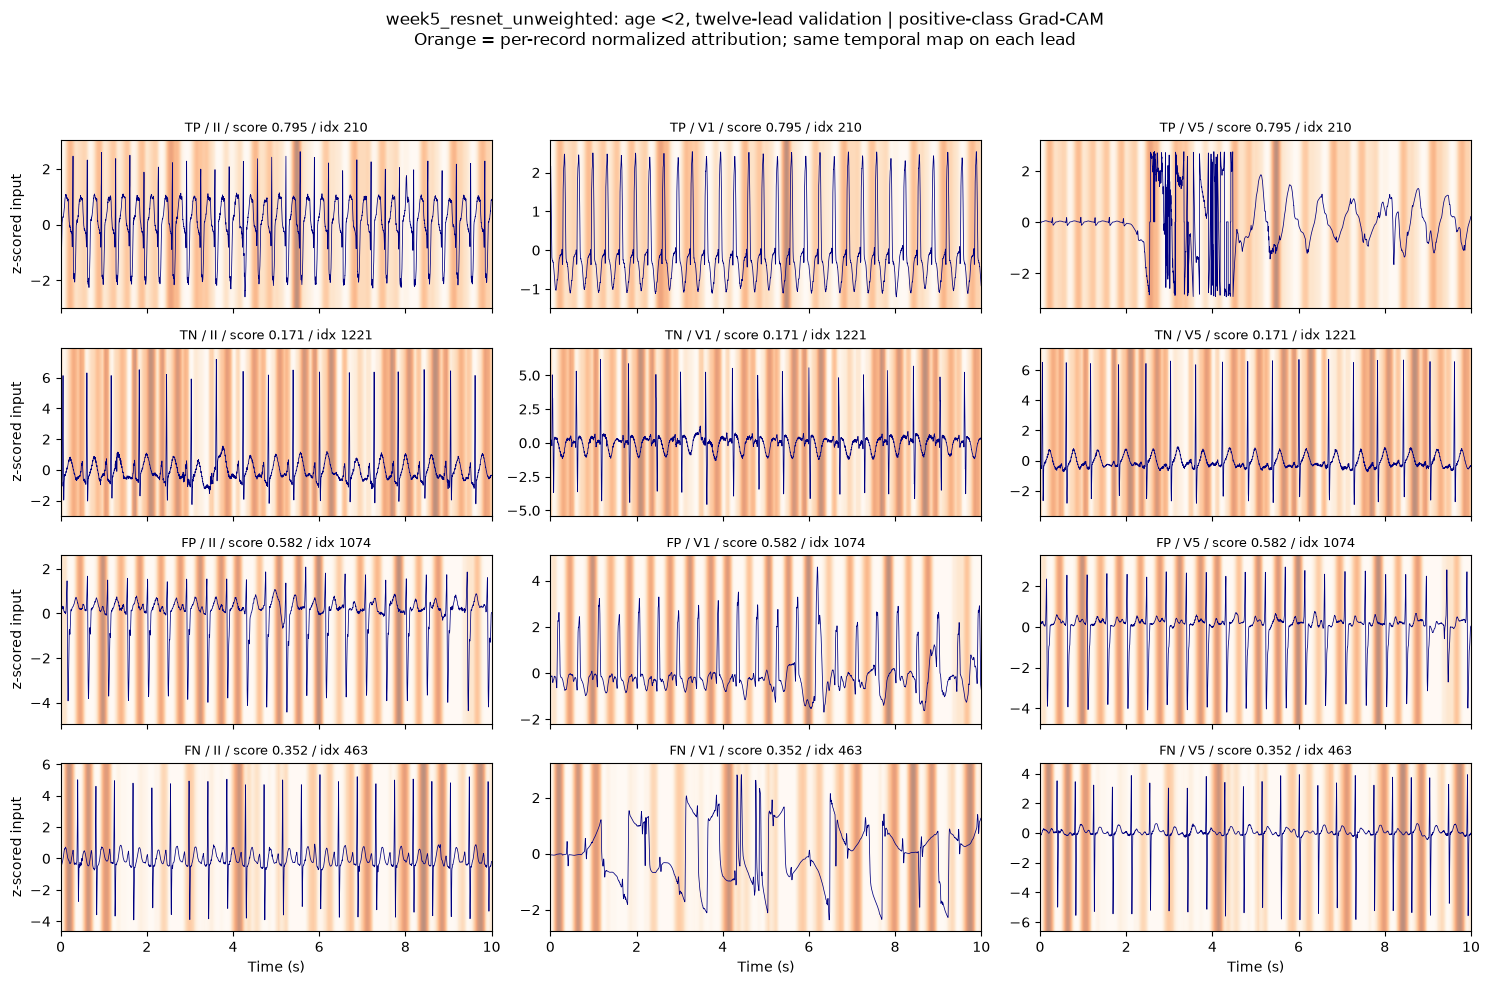

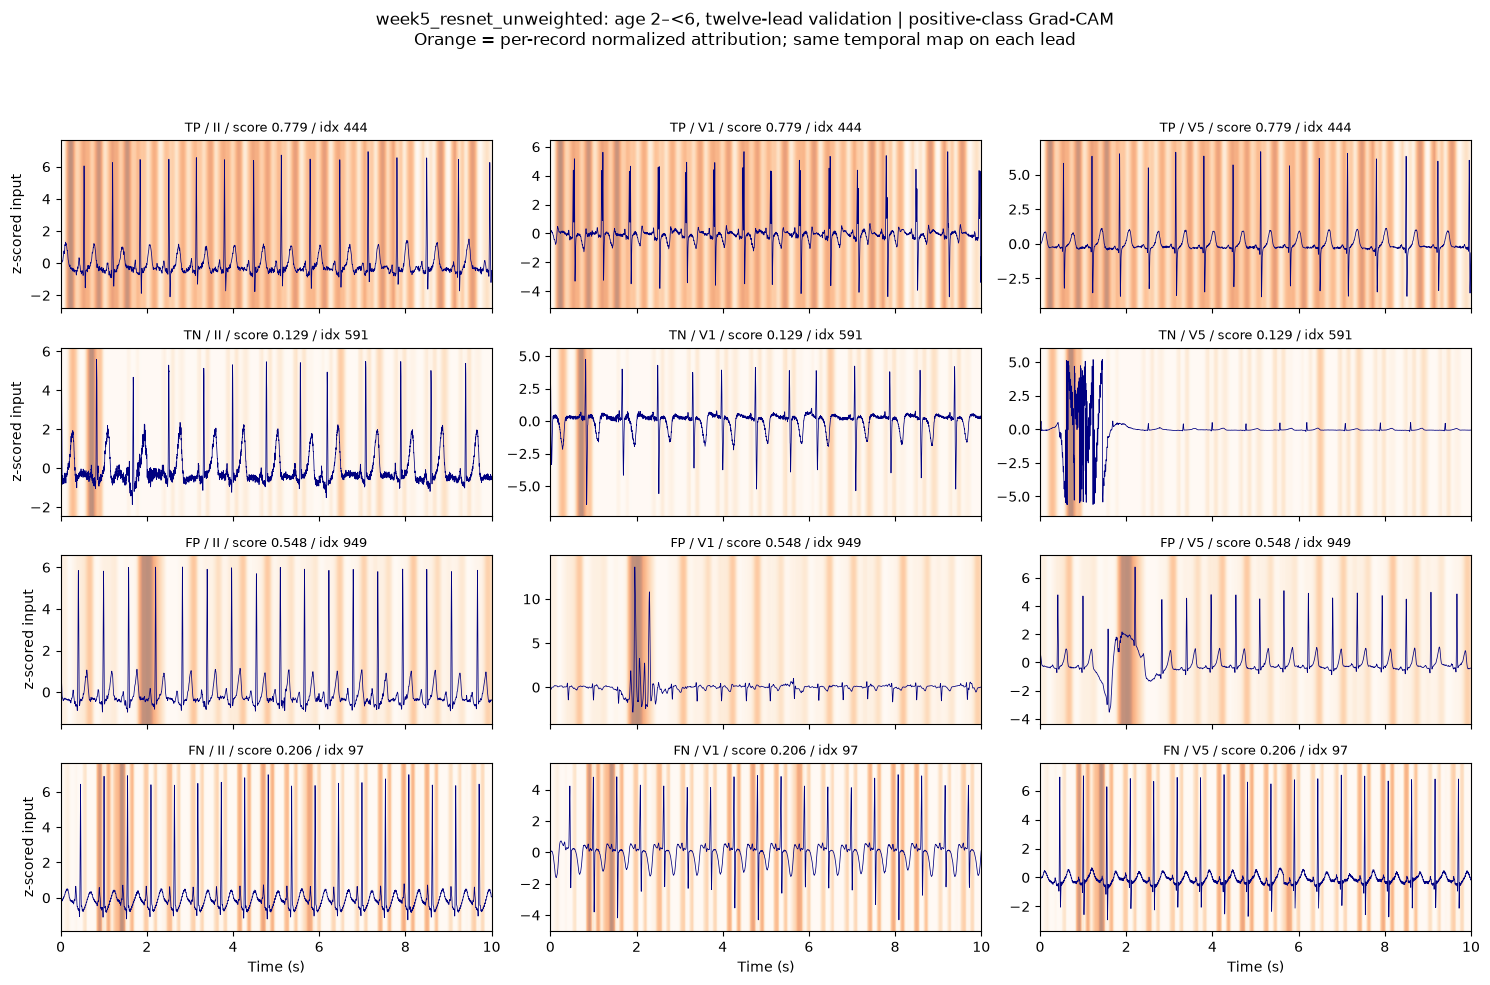

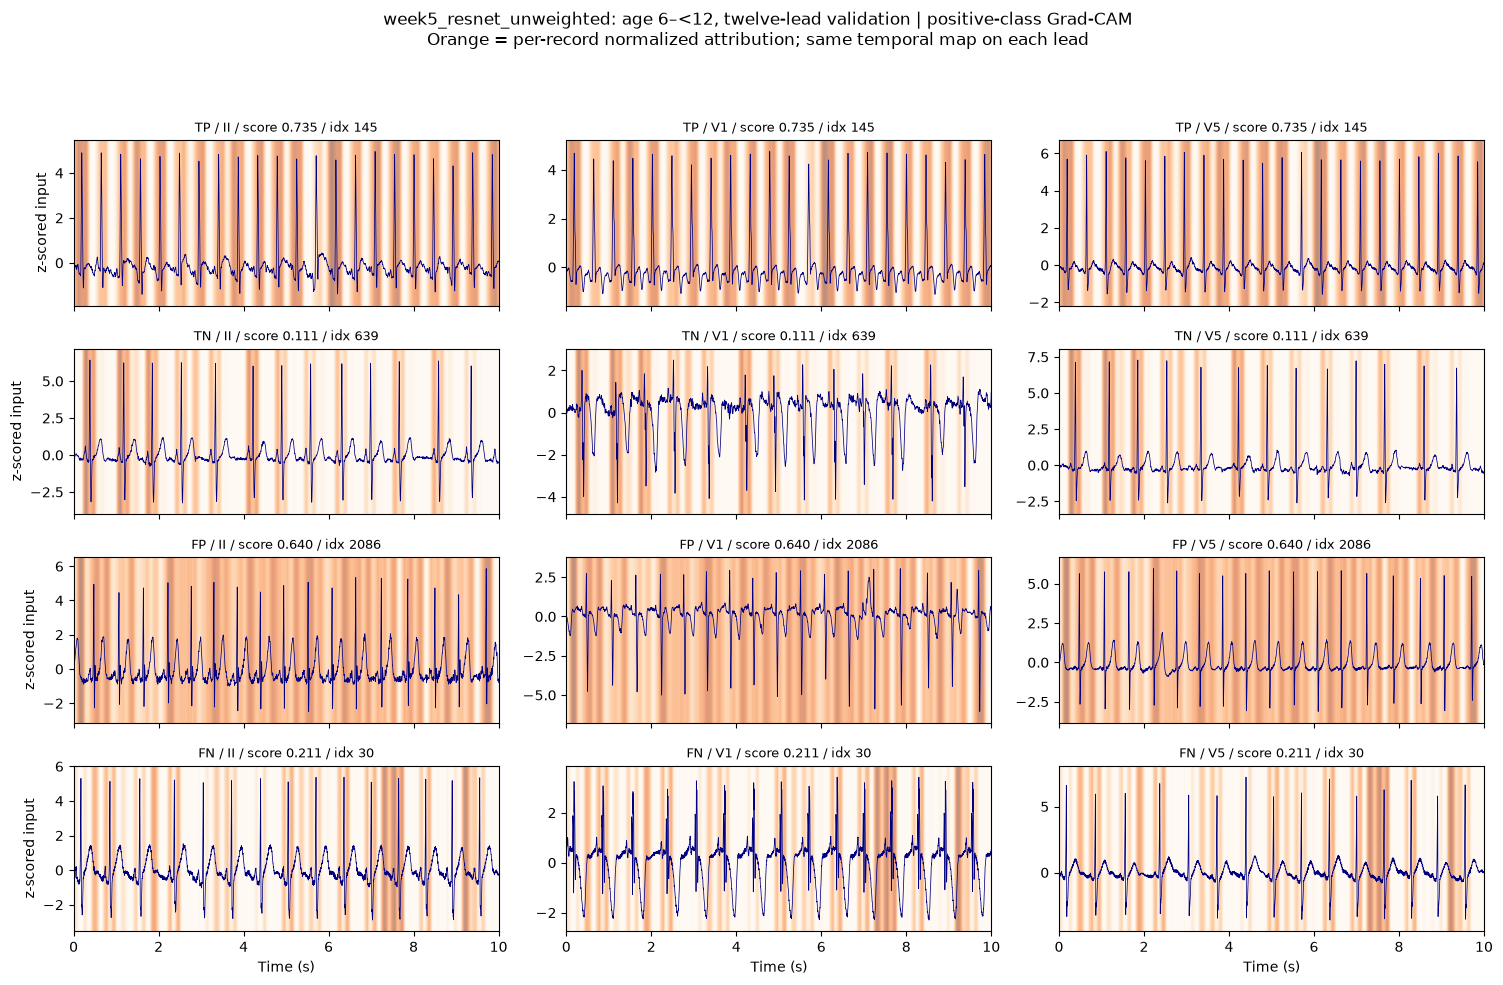

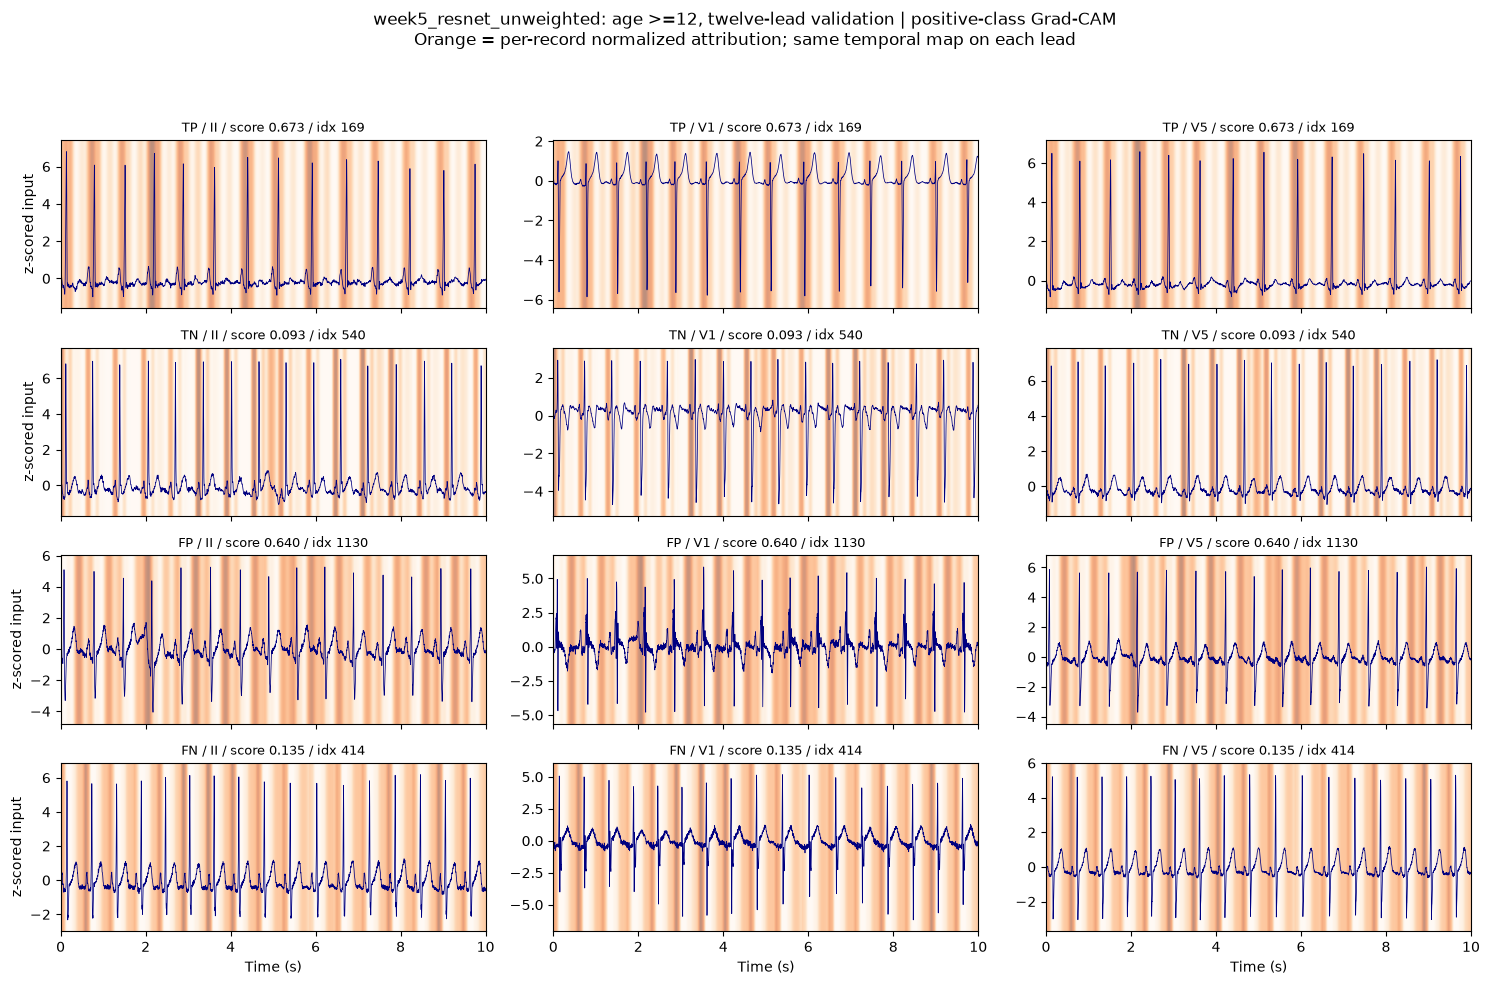

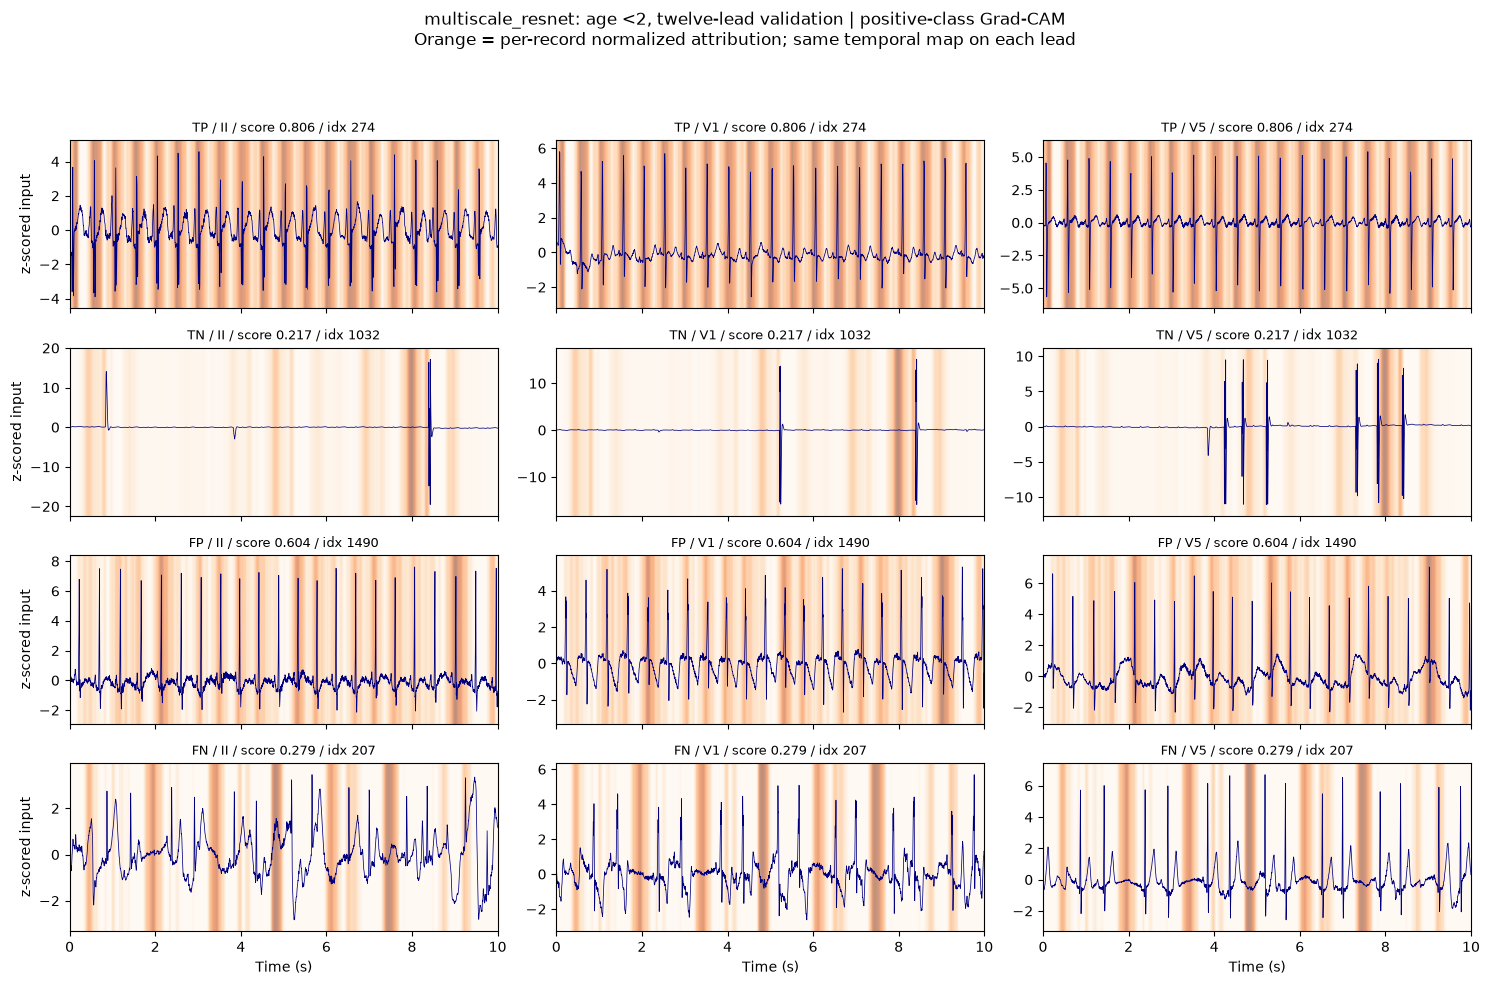

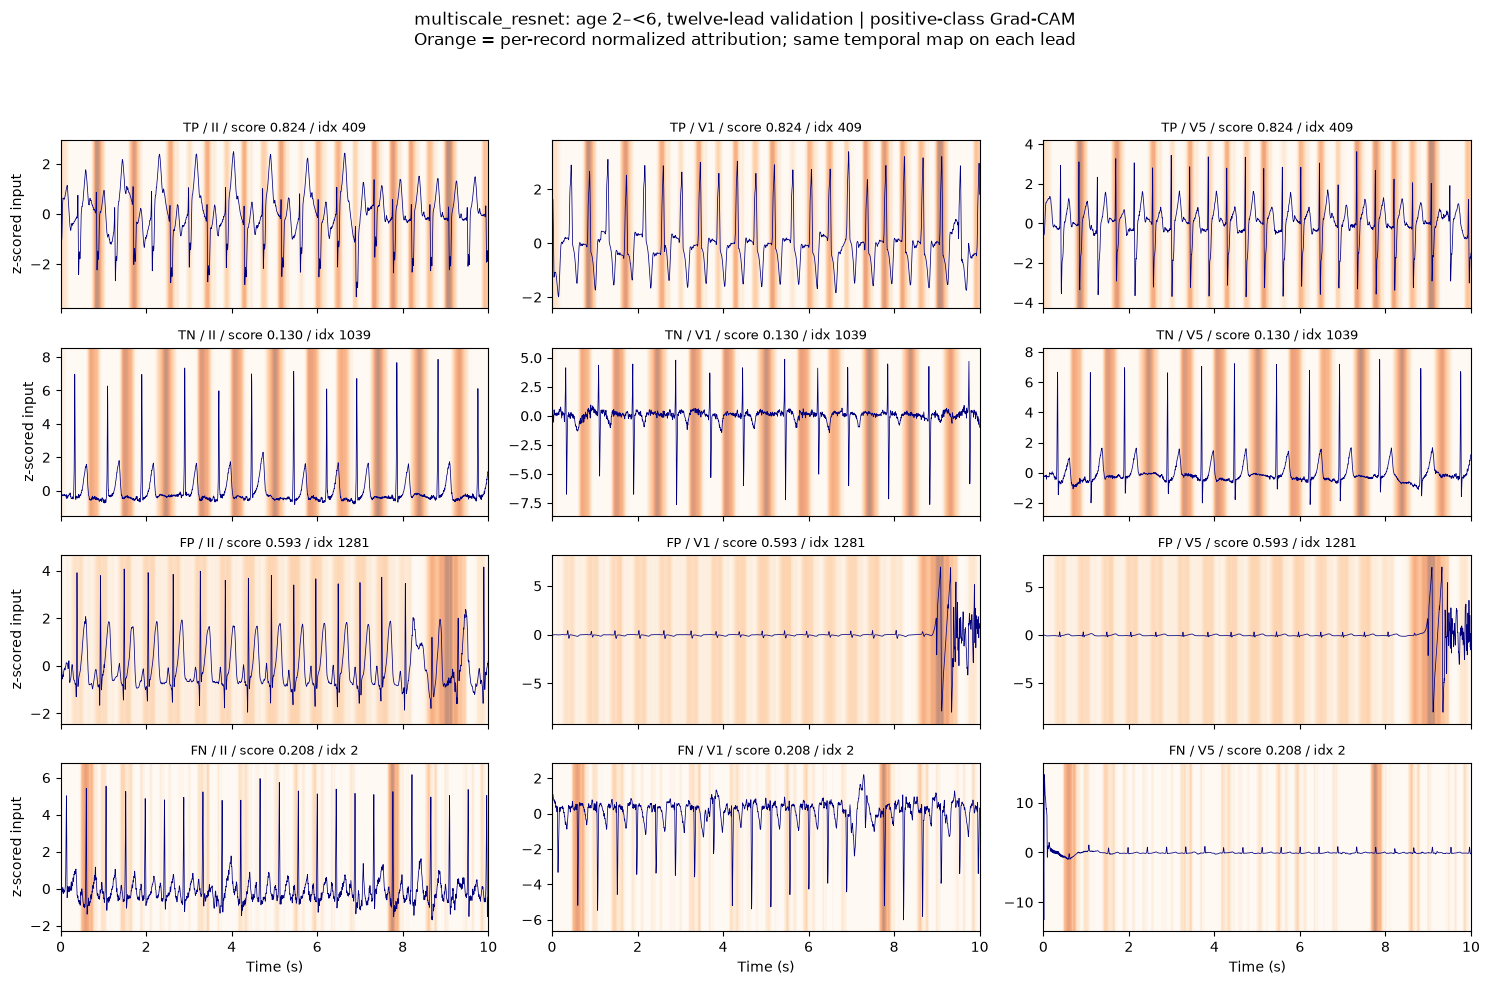

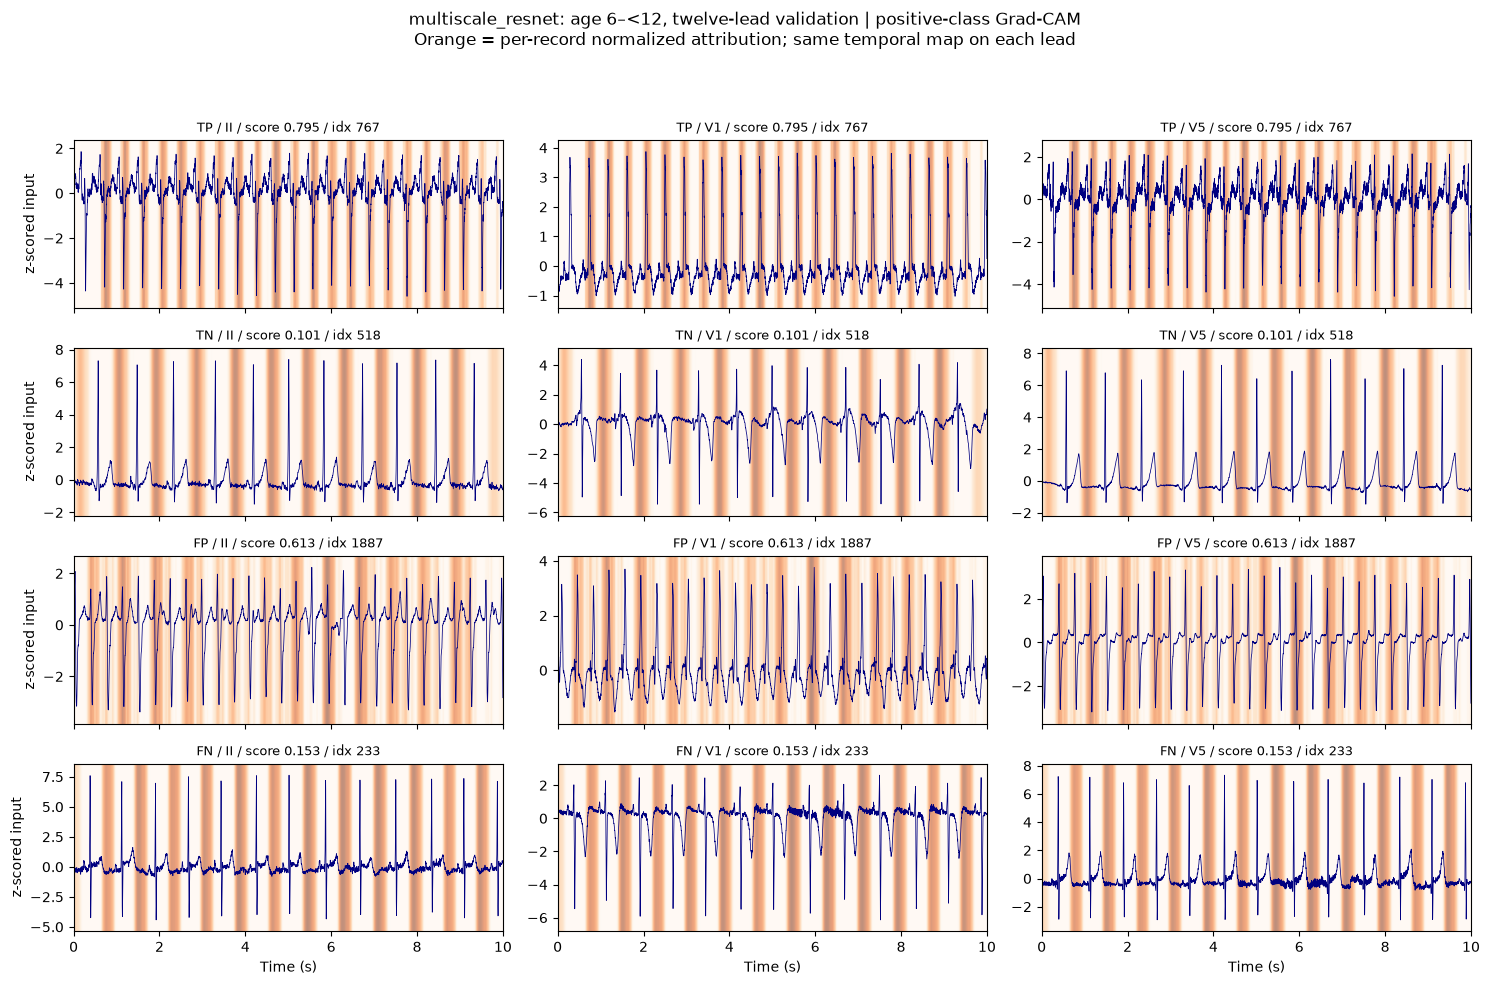

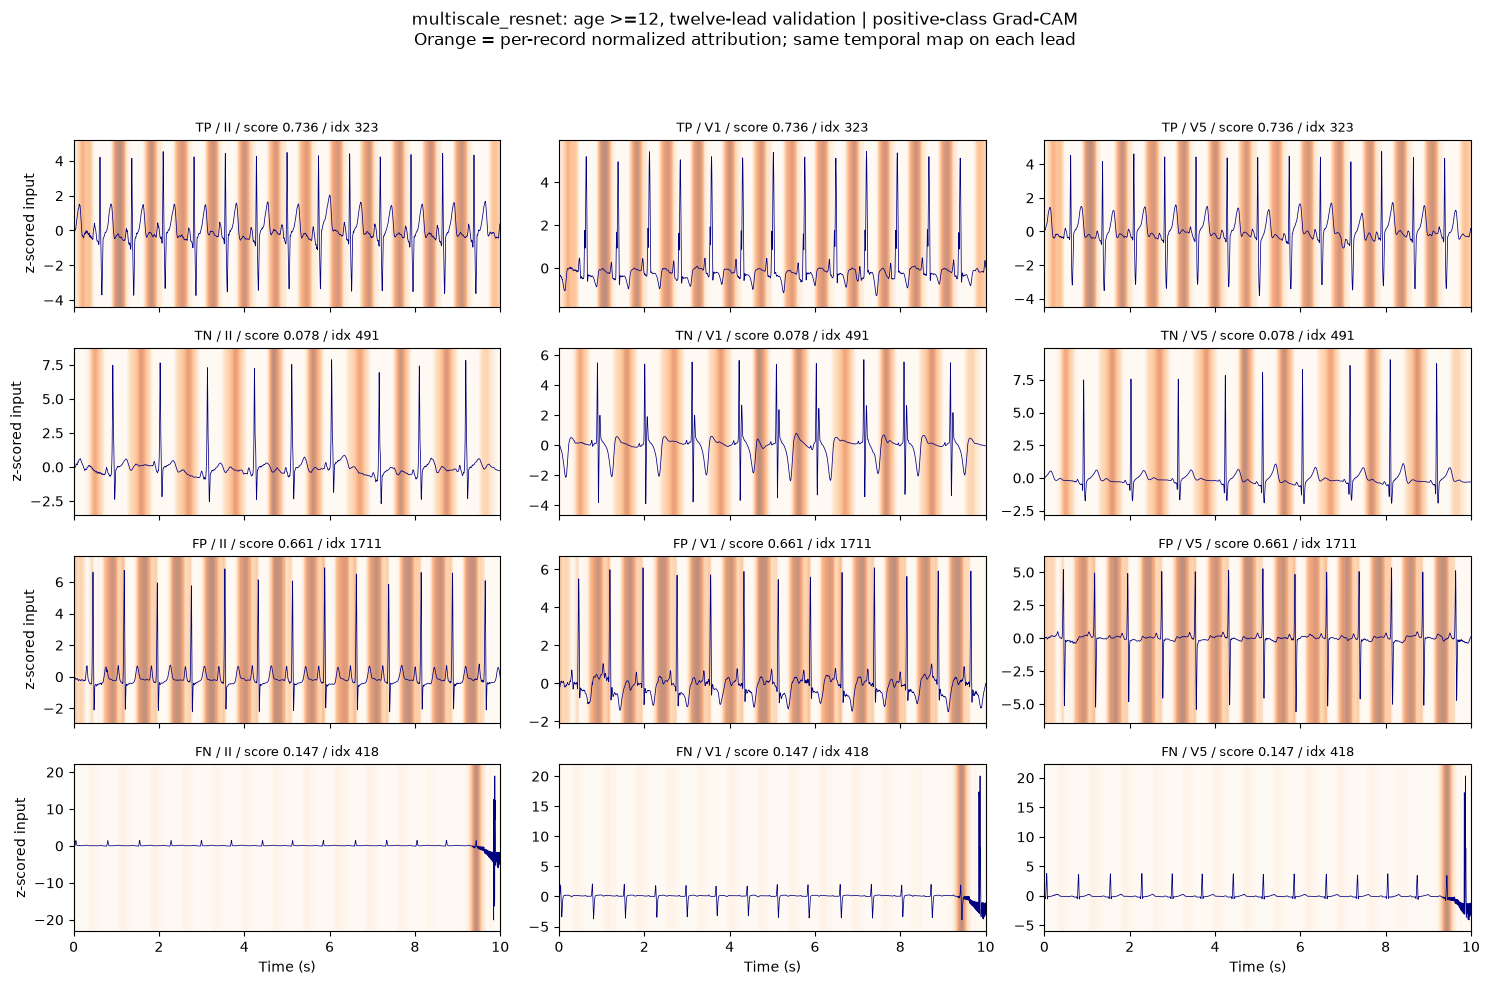

Saved eight architecture-separated age-group overlay figures.


In [4]:
summary=(case_results.groupby(['model','age_group','outcome'],observed=True)
         .agg(selected_cases=('validation_index','size'),selected_patients=('patient_id','nunique'),
              zero_maps=('zero_map','sum'),median_positive_score=('positive_score','median'),
              median_top_1s_mass_fraction=('top_1s_mass_fraction','median'),
              q25_top_1s_mass_fraction=('top_1s_mass_fraction',lambda s:s.quantile(.25)),
              q75_top_1s_mass_fraction=('top_1s_mass_fraction',lambda s:s.quantile(.75)))
         .reset_index())
summary.to_csv(OUT/'gradcam_summary.csv',index=False)
display(summary.round(3))
# Separate architecture figures; one predetermined median-score case per age × outcome.
SHOWN_LEADS=['II','V1','V5'];t=np.arange(N_SAMPLES)/FS
age_slug={'<2':'lt2','2–<6':'2to6','6–<12':'6to12','>=12':'ge12'}
for name in models:
    mapping={i:m for i,m in zip(indices[name],maps[name])}
    for age in AGE_GROUPS:
        fig,axes=plt.subplots(4,3,figsize=(15,10),sharex=True)
        for row,cat in enumerate(OUTCOMES):
            picked=case_results[(case_results.model==name)&(case_results.age_group==age)&
                                (case_results.outcome==cat)&(case_results.figure_case)]
            if picked.empty:
                for ax in axes[row]:ax.text(.5,.5,f'{cat}: no case',transform=ax.transAxes,ha='center');ax.axis('off')
                continue
            r=picked.iloc[0];idx=int(r.validation_index);x=load_input(frame.loc[idx]).numpy();raw=mapping[idx]
            cam=raw/raw.max() if raw.max()>0 else np.zeros_like(raw)
            for col,lead in enumerate(SHOWN_LEADS):
                ax=axes[row,col];trace=x[lead_index[lead]]
                lo=float(trace.min());hi=float(trace.max());pad=max(.1,(hi-lo)*.08);lo-=pad;hi+=pad
                ax.imshow(cam[None,:],extent=(0,N_SAMPLES/FS,lo,hi),aspect='auto',
                          cmap='Oranges',vmin=0,vmax=1,alpha=.52,zorder=0)
                ax.plot(t,trace,color='navy',linewidth=.55,zorder=2)
                ax.set_ylim(lo,hi);ax.set_xlim(0,10)
                ax.set_title(f'{cat} / {lead} / score {r.positive_score:.3f} / idx {idx}',fontsize=9)
                if col==0:ax.set_ylabel('z-scored input')
                if row==3:ax.set_xlabel('Time (s)')
        fig.suptitle(f'{name}: age {age}, twelve-lead validation | positive-class Grad-CAM\n'
                     'Orange = per-record normalized attribution; same temporal map on each lead',fontsize=12)
        fig.tight_layout(rect=[0,0,1,.94])
        fig.savefig(OUT/f'gradcam_{name}_age_{age_slug[age]}.png',dpi=150)
        plt.show()
        plt.close(fig)
print('Saved eight architecture-separated age-group overlay figures.')

In [5]:
# Post-hoc quality audit: quantify edge attribution and edge signal energy in the selected cases.
# This documents possible boundary/artifact sensitivity; it does not identify its cause.
edge_rows=[]
for name in models:
    saved=np.load(OUT/f'gradcam_raw_{name}.npz')
    for idx,raw in zip(saved['validation_indices'],saved['raw_maps']):
        row=frame.loc[int(idx)];x=load_input(row).numpy();energy=float((x*x).sum())
        edge_rows.append({'model':name,'validation_index':int(idx),'age_group':row.age_group,
                          'outcome':outcome(int(row.target),float(row[name+'_probability'])),
                          'last_0p5s_cam_mass':float(raw[-250:].sum()/raw.sum()) if raw.sum()>0 else np.nan,
                          'last_0p5s_signal_energy':float((x[:,-250:]**2).sum()/energy) if energy>0 else np.nan,
                          'max_abs_zscore':float(np.abs(x).max())})
edge=pd.DataFrame(edge_rows);edge.to_csv(OUT/'gradcam_edge_audit.csv',index=False)
print('Maps with >50% Grad-CAM mass in final 0.5 s:')
display(edge[edge.last_0p5s_cam_mass>.5].round(3))
print('Largest final-half-second signal energy shares:')
display(edge.nlargest(5,'last_0p5s_signal_energy').round(3))

Maps with >50% Grad-CAM mass in final 0.5 s:


,model,validation_index,age_group,outcome,last_0p5s_cam_mass,last_0p5s_signal_energy,max_abs_zscore
170,multiscale_resnet,1949,6–<12,TN,0.989,0.046,6.68


Largest final-half-second signal energy shares:


,model,validation_index,age_group,outcome,last_0p5s_cam_mass,last_0p5s_signal_energy,max_abs_zscore
214,multiscale_resnet,418,>=12,FN,0.118,0.721,24.724
12,week5_resnet_unweighted,1546,<2,TN,0.376,0.527,26.230
121,multiscale_resnet,1546,<2,FP,0.037,0.527,26.230
41,week5_resnet_unweighted,1242,2–<6,FP,0.166,0.475,8.983
35,week5_resnet_unweighted,1216,2–<6,TN,0.436,0.473,6.754


## Interpretation and limitations

**Observed maps.** The score-stratified selection produced 107 original-ResNet and 111 multi-scale maps across the four ages and four prediction outcomes. Every case was selected by age, outcome, patient uniqueness, and score rank before viewing its heatmap. The original ResNet has only two <2-year false positives in the full twelve-lead pool, so that cell has two maps; the multi-scale ≥12-year true-positive pool has six patients, so that cell has six. All other cells have seven. All selected maps had nonzero positive-class Grad-CAM output. The overlay figures show repeated temporal bands in many records, along with variable broader or more localized intervals. The same temporal map is displayed on leads II, V1, and V5 for context; it is **not lead-specific importance**.

The top-one-second positive-CAM mass fractions vary within age/outcome cells. For true positives, median fractions across ages were 0.117–0.144 for the original ResNet and 0.142–0.154 for the multi-scale model. There is no clear monotonic age pattern in this small, score-selected summary. Other outcome cells vary more, but some have few eligible patients and the maps depend on model, layer, class logit, and per-record scaling. Raw heat intensity is not compared between architectures.

**Quality observations.** The edge audit found one selected multi-scale true negative (validation index 1949, age 6–<12) with 98.9% of positive-class CAM mass in the final 0.5 second, despite only 4.6% of normalized signal energy there. A displayed multi-scale ≥12 false negative (index 418) has a large end-of-window deflection and 72.1% of normalized signal energy in the final 0.5 second; its CAM mass in that interval is 11.8%. These are observable boundary/signal anomalies, not diagnoses or proof of a model shortcut. They warn against reading isolated highlighted intervals as pathology.

**Interpretation boundary.** Grad-CAM here identifies where the chosen positive-class logit is sensitive in selected validation examples. It does not show which lead caused a prediction, establish QRS-specific pathology, explain why age-wise sensitivity differs, or prove clinical causality. ReLU clipping omits negative evidence, particularly relevant to false negatives. The quantile-selected maps are not population-level attribution estimates. No test records were used; no threshold or checkpoint was changed.